<a href="https://colab.research.google.com/github/syzh1714/WIE-Poke/blob/main/WIE_tech1_poke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [74]:

url = "https://raw.githubusercontent.com/KeithGalli/pandas/master/pokemon_data.csv"
df = pd.read_csv(url)


df.rename(columns={
    'Name': 'Name',
    'Type 1': 'Type 1',
    'HP': 'HP',
    'Attack': 'Attack',
    'Defense': 'Defense',
    'Sp. Atk': 'Sp. Atk',
    'Sp. Def': 'Sp. Def',
    'Speed': 'Speed',
    'Legendary': 'Legendary'
}, inplace=True)

# Define core battle stats
features = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']

# Create a 'Total_Power' column by summing all base stats
df['Total_Power'] = df[features].sum(axis=1)

print(f"Dataset loaded successfully! Total Pokémon: {len(df)}")

Dataset loaded successfully! Total Pokémon: 800



--- POWER COMPARISON SUMMARY (Average Total Stats) ---
Legendary
False    417.213605
True     637.384615
Name: Total_Power, dtype: float64




/tmp/ipykernel_1472/3648268790.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Legendary', y='Total_Power', data=df, palette='Set2')


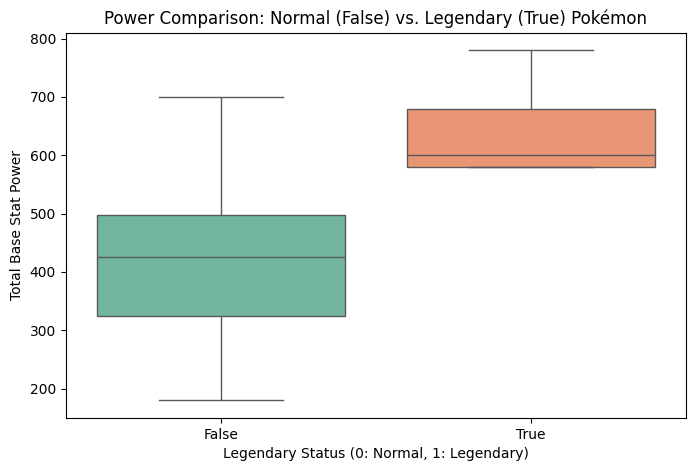

In [75]:
#Power comparison
print("\n--- POWER COMPARISON SUMMARY (Average Total Stats) ---")
power_summary = df.groupby('Legendary')['Total_Power'].mean()
print(power_summary)
print("\n")
plt.figure(figsize=(8, 5))
sns.boxplot(x='Legendary', y='Total_Power', data=df, palette='Set2')
plt.title('Power Comparison: Normal (False) vs. Legendary (True) Pokémon')
plt.xlabel('Legendary Status (0: Normal, 1: Legendary)')
plt.ylabel('Total Base Stat Power')
plt.show()

In [76]:
X = df[features]
y = df['Legendary'].astype(int) # Convert True/False to 1/0

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features for KNN (essential for distance-based algorithms)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Model 2: K-Nearest Neighbors Classifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

Decision Tree Accuracy: 95.62%
K-Nearest Neighbors Accuracy: 92.50%



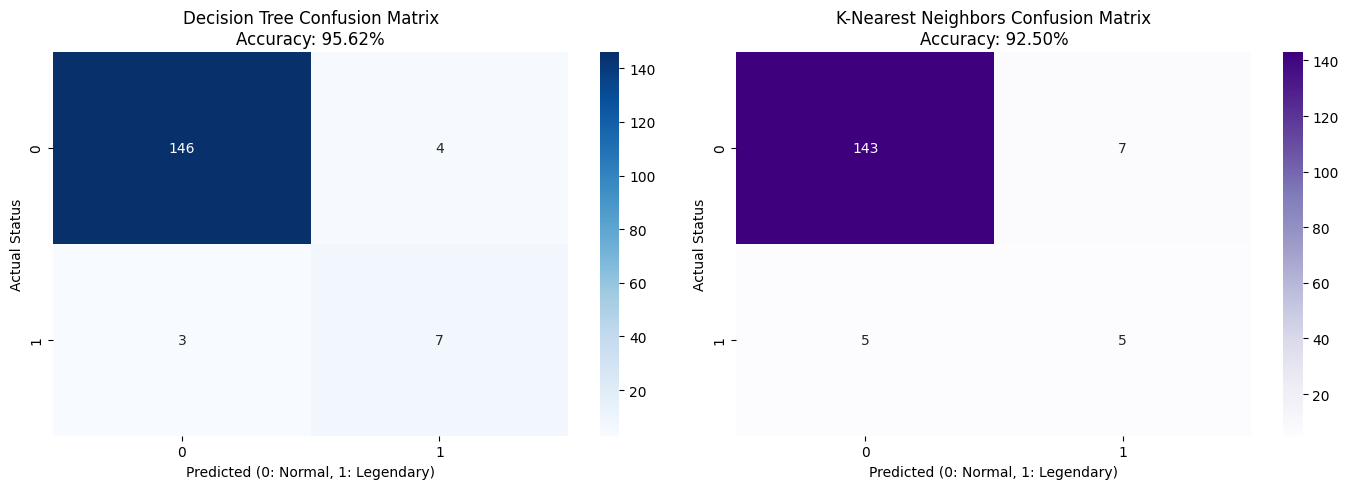

In [77]:
y_pred_dt = dt_model.predict(X_test)
y_pred_knn = knn_model.predict(X_test_scaled)

acc_dt = accuracy_score(y_test, y_pred_dt)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f"Decision Tree Accuracy: {acc_dt * 100:.2f}%")
print(f"K-Nearest Neighbors Accuracy: {acc_knn * 100:.2f}%\n")

# Display Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f"Decision Tree Confusion Matrix\nAccuracy: {acc_dt*100:.2f}%")
axes[0].set_xlabel("Predicted (0: Normal, 1: Legendary)")
axes[0].set_ylabel("Actual Status")

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Purples', ax=axes[1])
axes[1].set_title(f"K-Nearest Neighbors Confusion Matrix\nAccuracy: {acc_knn*100:.2f}%")
axes[1].set_xlabel("Predicted (0: Normal, 1: Legendary)")
axes[1].set_ylabel("Actual Status")

plt.tight_layout()
plt.show()

In [78]:
# Create a weighted Combat Score where Speed and Offense carry tactical weight
df['Combat_Score'] = (
    (df['Attack'] * 1.1) +
    (df['Sp. Atk'] * 1.1) +
    (df['Defense'] * 1.0) +
    (df['Sp. Def'] * 1.0) +
    (df['Speed'] * 1.3) +
    (df['HP'] * 0.8)
)

def pokemon_matchups(pokemon_name, df):
    match = df[df['Name'].str.lower() == pokemon_name.lower()]
    if match.empty:
        return print(f"Pokémon '{pokemon_name}' not found in dataset.")

    target = match.iloc[0]
    print(f"\n==================================================================")
    print(f"⚔️ ADVANCED TACTICAL BATTLE ANALYSIS FOR: {target.Name.upper()} ⚔️")
    print(f"Type: {target['Type 1']} | Legendary: {target['Legendary']} | Combat Score: {target['Combat_Score']:.1f}")
    print(f"Base Stats -> HP: {target.HP} | Atk: {target.Attack} | Def: {target.Defense} | Sp.Atk: {target['Sp. Atk']} | Sp.Def: {target['Sp. Def']} | Speed: {target.Speed}")
    print(f"==================================================================")

    # Favorable Matchups (Lower Combat Score, but let's highlight their individual stats)
    wins = df[df['Combat_Score'] < target['Combat_Score']].sort_values(by='Combat_Score', ascending=False).head(5)
    print("\n🟢 Favorable Matchups (Likely Wins due to Stat Advantage):")
    for _, row in wins.iterrows():
        print(f"   • {row['Name']} (Score: {row['Combat_Score']:.1f}) | Speed: {row['Speed']} | Def: {row['Defense']} | Sp.Atk: {row['Sp. Atk']}")

    # Challenging Matchups (Higher Combat Score)
    losses = df[df['Combat_Score'] > target['Combat_Score']].sort_values(by='Combat_Score', ascending=True).head(5)
    print("\n🔴 Challenging Matchups (Likely Losses due to Stat Disadvantage):")
    for _, row in losses.iterrows():
        print(f"   • {row['Name']} (Score: {row['Combat_Score']:.1f}) | Speed: {row['Speed']} | Def: {row['Defense']} | Sp.Atk: {row['Sp. Atk']}")
    print(f"==================================================================")



In [79]:
user_input = input("Enter any Pokémon name to analyze : ")
pokemon_matchups(user_input, df)

Enter any Pokémon name to analyze : Mew

⚔️ ADVANCED TACTICAL BATTLE ANALYSIS FOR: MEW ⚔️
Type: Psychic | Legendary: False | Combat Score: 630.0
Base Stats -> HP: 100 | Atk: 100 | Def: 100 | Sp.Atk: 100 | Sp.Def: 100 | Speed: 100

🟢 Favorable Matchups (Likely Wins due to Stat Advantage):
   • Dragonite (Score: 629.2) | Speed: 80 | Def: 95 | Sp.Atk: 100
   • Volcanion (Score: 629.0) | Speed: 70 | Def: 120 | Sp.Atk: 130
   • HeracrossMega Heracross (Score: 629.0) | Speed: 75 | Def: 115 | Sp.Atk: 40
   • Metagross (Score: 628.0) | Speed: 70 | Def: 130 | Sp.Atk: 95
   • MeloettaAria Forme (Score: 627.5) | Speed: 90 | Def: 77 | Sp.Atk: 128

🔴 Challenging Matchups (Likely Losses due to Stat Disadvantage):
   • DeoxysDefense Forme (Score: 631.0) | Speed: 90 | Def: 160 | Sp.Atk: 70
   • HoopaHoopa Confined (Score: 631.0) | Speed: 70 | Def: 60 | Sp.Atk: 150
   • AmpharosMega Ampharos (Score: 631.5) | Speed: 45 | Def: 105 | Sp.Atk: 165
   • Hydreigon (Score: 634.0) | Speed: 98 | Def: 90 | Sp.Atk